Cell 1 – Install and import libraries

In [1]:
!pip install mlxtend

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from mlxtend.frequent_patterns import apriori
from mlxtend.frequent_patterns import association_rules

from mlxtend.preprocessing import TransactionEncoder

import warnings
warnings.filterwarnings('ignore')

Cell 2 – Upload dataset

In [3]:
from google.colab import files

uploaded = files.upload()

filename = next(iter(uploaded))

df = pd.read_csv("Groceries_dataset.csv.zip")

print("Dataset loaded successfully!")
display(df.head())

Saving Groceries_dataset.csv.zip to Groceries_dataset.csv (1).zip
Dataset loaded successfully!


,Member_number,Date,itemDescription
0,1808,21-07-2015,tropical fruit
1,2552,05-01-2015,whole milk
2,2300,19-09-2015,pip fruit
3,1187,12-12-2015,other vegetables
4,3037,01-02-2015,whole milk


Cell 3 – Understand the dataset

In [4]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nColumns:")
print(df.columns)

Dataset Shape: (38765, 3)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 38765 entries, 0 to 38764
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Member_number    38765 non-null  int64 
 1   Date             38765 non-null  object
 2   itemDescription  38765 non-null  object
dtypes: int64(1), object(2)
memory usage: 908.7+ KB

Missing Values:
Member_number      0
Date               0
itemDescription    0
dtype: int64

Columns:
Index(['Member_number', 'Date', 'itemDescription'], dtype='object')


Cell 4 – Data preprocessing

In [5]:
df['Date'] = pd.to_datetime(df['Date'])

df = df.dropna(
    subset=['Member_number', 'Date', 'itemDescription']
)

df['itemDescription'] = (
    df['itemDescription'].str.strip().str.lower()
)

transactions = (
    df.groupby(['Member_number', 'Date'])['itemDescription']
    .apply(list)
    .tolist()
)

print("Total Transactions:", len(transactions))
print("Sample Transactions:")
print(transactions[:5])

Total Transactions: 14963
Sample Transactions:
[['whole milk', 'pastry', 'salty snack'], ['sausage', 'whole milk', 'semi-finished bread', 'yogurt'], ['soda', 'pickled vegetables'], ['canned beer', 'misc. beverages'], ['sausage', 'hygiene articles']]


Cell 5 – Convert transactions into a basket format

In [6]:
encoder = TransactionEncoder()

encoded_data = encoder.fit(transactions).transform(transactions)

basket = pd.DataFrame(
    encoded_data,
    columns=encoder.columns_
)

print("Basket Dataset:")
display(basket.head())

Basket Dataset:


,abrasive cleaner,artif. sweetener,baby cosmetics,bags,baking powder,bathroom cleaner,beef,berries,beverages,bottled beer,...,uht-milk,vinegar,waffles,whipped/sour cream,whisky,white bread,white wine,whole milk,yogurt,zwieback
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,True,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


Cell 6 – Find frequent itemsets

In [7]:
frequent_items = apriori(
    basket,
    min_support=0.01,
    use_colnames=True
)

frequent_items = frequent_items.sort_values(
    by='support',
    ascending=False
)

display(frequent_items.head(15))

,support,itemsets
62,0.157923,(whole milk)
39,0.122101,(other vegetables)
45,0.110005,(rolls/buns)
51,0.097106,(soda)
63,0.085879,(yogurt)
46,0.069572,(root vegetables)
56,0.067767,(tropical fruit)
4,0.060683,(bottled water)
48,0.060349,(sausage)
14,0.053131,(citrus fruit)


Cell 7 – Generate association rules

In [8]:
rules = association_rules(
    frequent_items,
    metric='confidence',
    min_threshold=0.1
)

rules = rules.sort_values(
    by='lift',
    ascending=False
)

display(
    rules[['antecedents', 'consequents',
           'support', 'confidence', 'lift']].head(15)
)

,antecedents,consequents,support,confidence,lift
3,(yogurt),(whole milk),0.011161,0.129961,0.822940
1,(rolls/buns),(whole milk),0.013968,0.126974,0.804028
0,(other vegetables),(whole milk),0.014837,0.121511,0.769430
2,(soda),(whole milk),0.011629,0.119752,0.758296


Cell 8 – Filter strong association rules

In [9]:
strong_rules = rules[
    (rules['confidence'] >= 0.3) &
    (rules['lift'] > 1)
]

display(
    strong_rules[['antecedents', 'consequents',
                  'support', 'confidence', 'lift']]
)

,antecedents,consequents,support,confidence,lift


Cell 9 – Visualize association rules

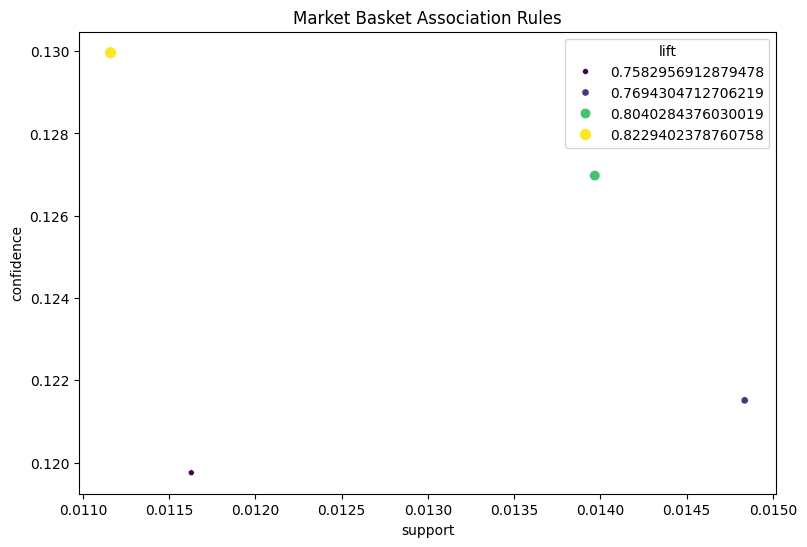

In [10]:
plt.figure(figsize=(9,6))

sns.scatterplot(
    data=rules,
    x='support',
    y='confidence',
    size='lift',
    hue='lift',
    palette='viridis'
)

plt.title('Market Basket Association Rules')
plt.show()

Cell 10 – Save results

In [11]:
rules.to_csv(
    'Market_Basket_Association_Rules.csv',
    index=False
)

print("Association rules saved successfully!")

files.download('Market_Basket_Association_Rules.csv')

Association rules saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>